# Import Libraries

In [ ]:
import math
#Data Loading
import pandas  as pd
##Preprocessing
import numpy   as np
from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA

#Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.cluster.hierarchy import fcluster

#Density-Based Clustering
from sklearn.cluster import DBSCAN

#SOM Clustering
from minisom import MiniSom

# Kmeans
from sklearn.cluster import KMeans

# C-means
import skfuzzy as fuzz

#PSO
from sklearn.metrics import pairwise_distances_argmin

#plot
import matplotlib.pyplot as plt

from sklearn.metrics import silhouette_score
import seaborn as sns
from sklearn.metrics import  davies_bouldin_score, calinski_harabasz_score
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, fowlkes_mallows_score, accuracy_score
from scipy.optimize import linear_sum_assignment

# Preprocessing

In [ ]:
df = pd.read_csv("diabetes.csv")
df.shape

(768, 9)

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [5]:
df.nunique()

Pregnancies                  17
Glucose                     136
BloodPressure                47
SkinThickness                51
Insulin                     186
BMI                         248
DiabetesPedigreeFunction    517
Age                          52
Outcome                       2
dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [8]:
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
print("ستون‌های عددی:", numeric_cols)

if 'Outcome' in numeric_cols:
    numeric_cols.remove('Outcome')
    print("'Outcome' removed from numeric_cols")

categorical_cols = ['Outcome']
print("ستون‌های دسته‌بندی:", categorical_cols)

ستون‌های عددی: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
'Outcome' removed from numeric_cols
ستون‌های دسته‌بندی: ['Outcome']


In [9]:
df.Outcome.unique()
df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

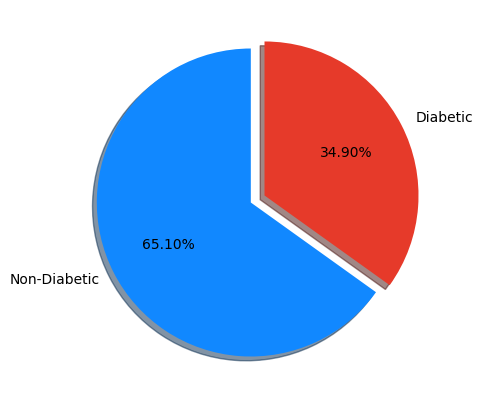

In [10]:
percentage = df.Outcome.value_counts(normalize=True)*100
labels = ["Non-Diabetic","Diabetic"]

# Plot PieChart with Ploty library
fig, ax = plt.subplots(figsize =(10, 5))
explode = (0, 0.1)
colors = ['#1188ff','#e63a2a']
ax.pie(percentage, labels = labels, startangle = 90,
       autopct='%1.2f%%',explode=explode, shadow=True, colors=colors)
plt.show()

In [11]:
df['Age'].value_counts()

Age
22    72
21    63
25    48
24    46
23    38
28    35
26    33
27    32
29    29
31    24
41    22
30    21
37    19
42    18
33    17
36    16
38    16
32    16
45    15
34    14
46    13
40    13
43    13
39    12
35    10
44     8
50     8
51     8
52     8
58     7
54     6
47     6
49     5
60     5
53     5
57     5
48     5
63     4
66     4
55     4
62     4
59     3
56     3
65     3
67     3
61     2
69     2
72     1
81     1
64     1
70     1
68     1
Name: count, dtype: int64

In [13]:
df.min()

Pregnancies                  0.000
Glucose                      0.000
BloodPressure                0.000
SkinThickness                0.000
Insulin                      0.000
BMI                          0.000
DiabetesPedigreeFunction     0.078
Age                         21.000
Outcome                      0.000
dtype: float64

In [14]:
df.max()

Pregnancies                  17.00
Glucose                     199.00
BloodPressure               122.00
SkinThickness                99.00
Insulin                     846.00
BMI                          67.10
DiabetesPedigreeFunction      2.42
Age                          81.00
Outcome                       1.00
dtype: float64

In [15]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

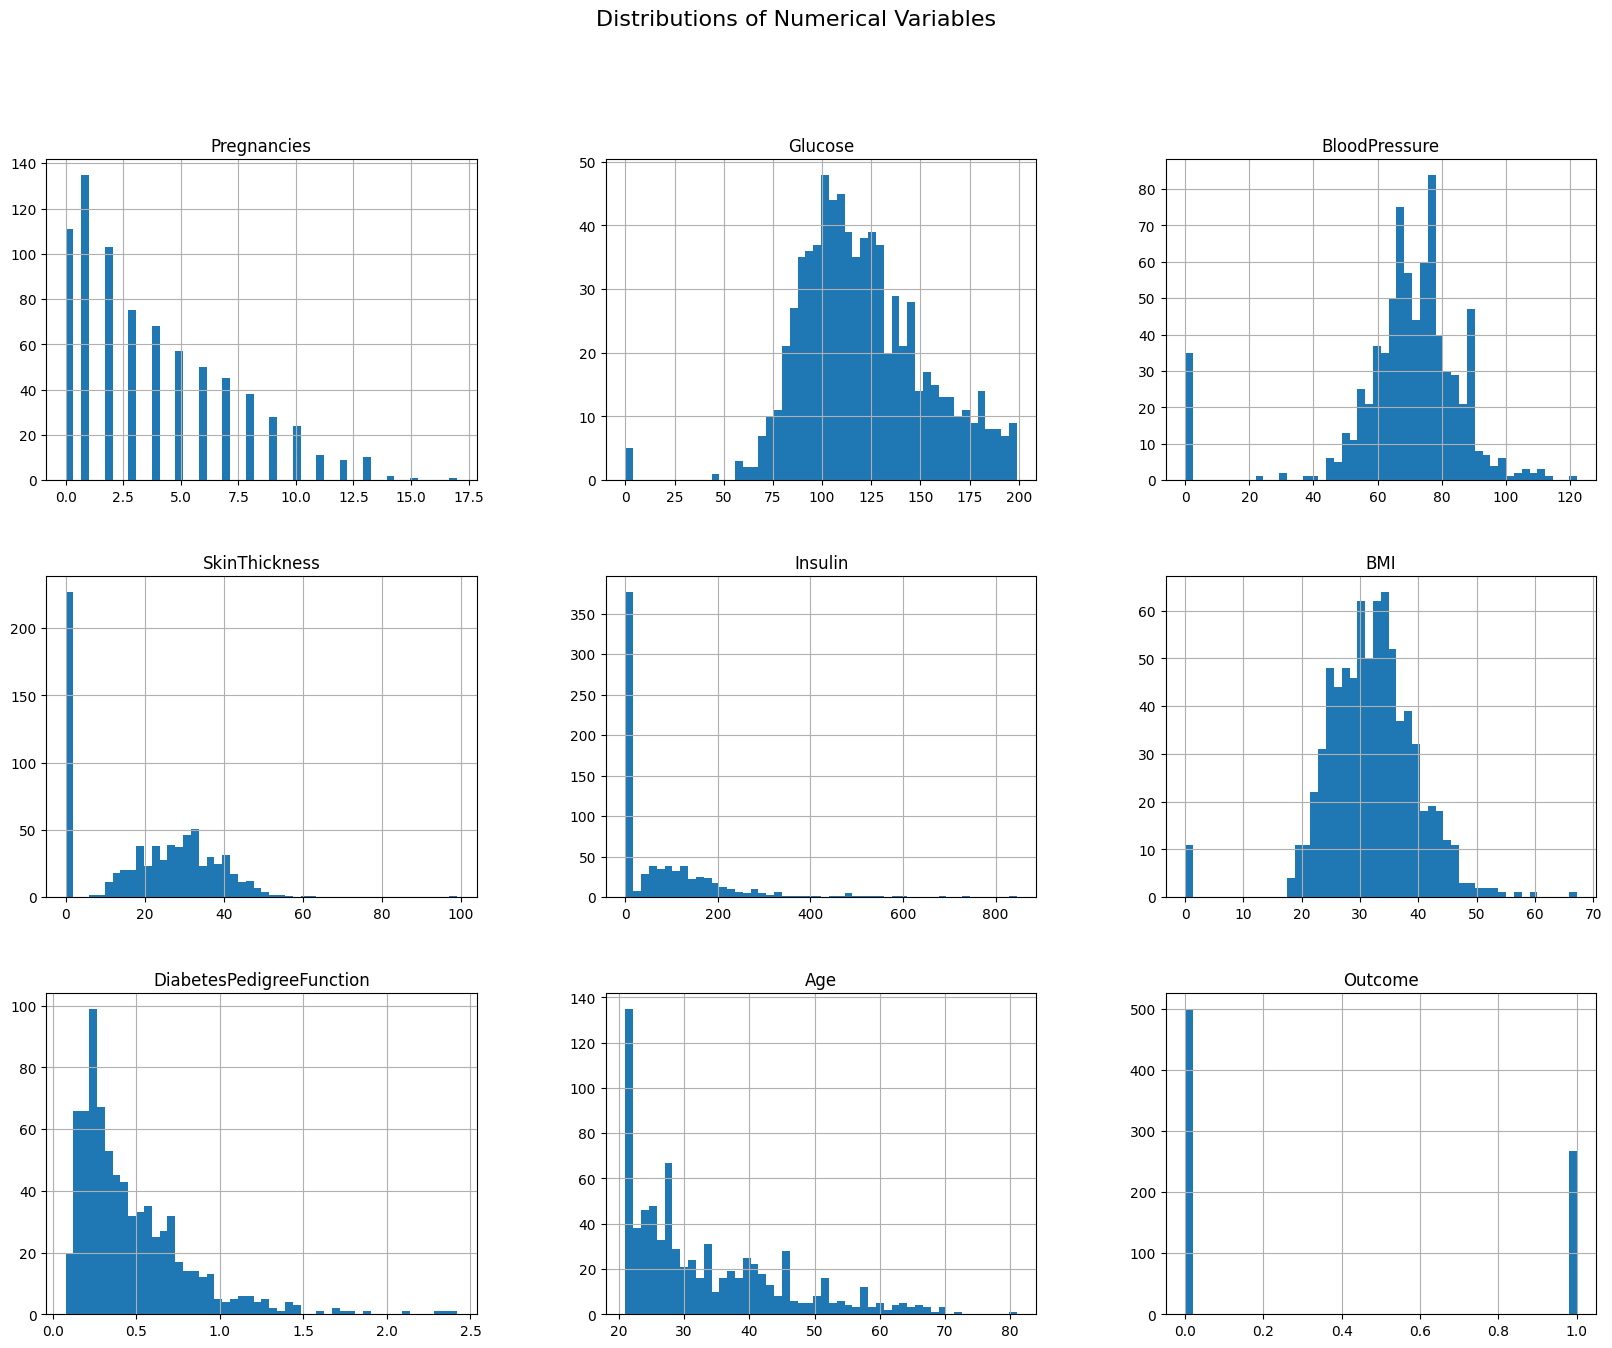

In [ ]:
df.hist(bins=50, figsize=(20, 15))
plt.suptitle("Distributions of Numerical Variables", fontsize=16)
plt.show()

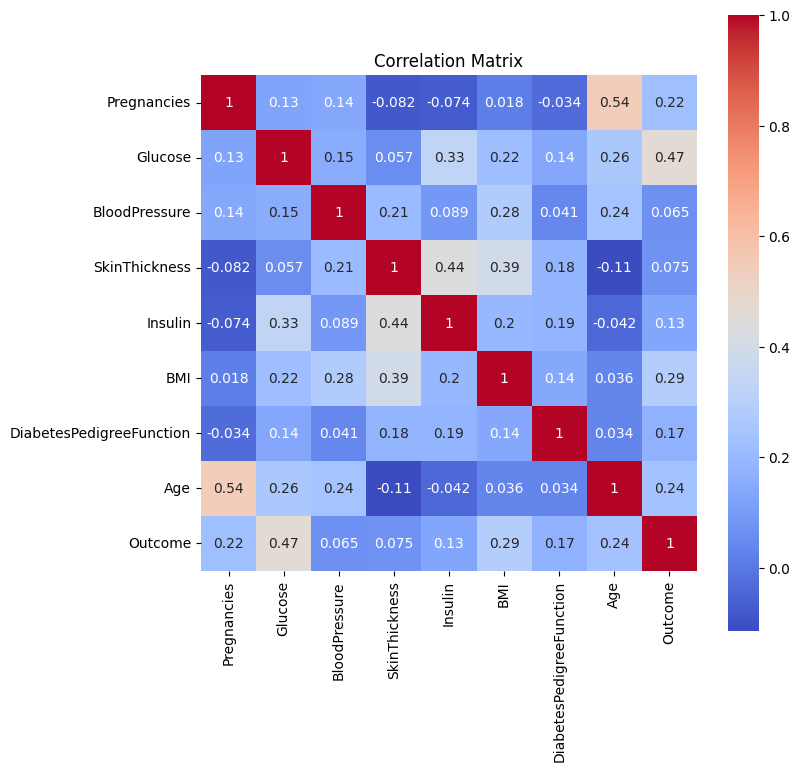

In [17]:
def plotCorrelationMatrix(df, size):
    plt.figure(figsize=(size, size))
    sns.heatmap(df.corr(), annot=True, cmap='coolwarm', square=True)
    plt.title("Correlation Matrix")
    plt.show()

plotCorrelationMatrix(df, 8)

<Axes: >

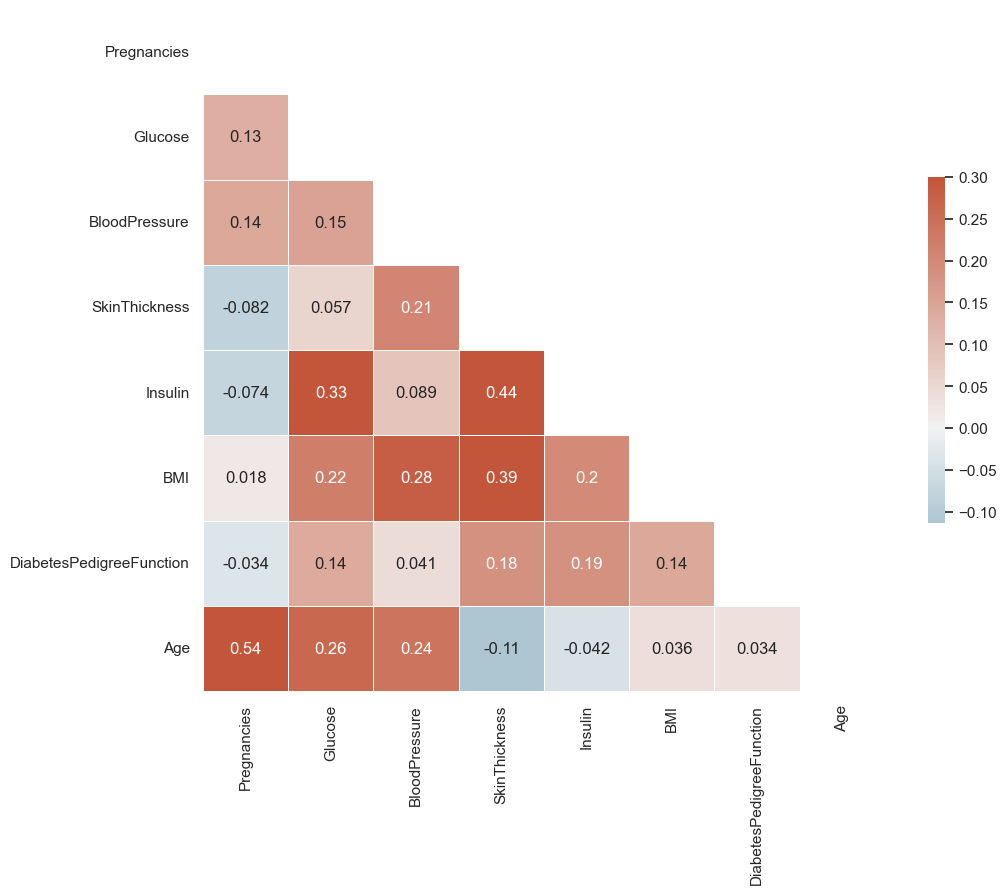

In [ ]:
sns.set_theme(style="white")

d = df.drop(['Outcome'], axis=1)


corr = d.corr()

mask = np.triu(np.ones_like(corr, dtype=bool))


f, ax = plt.subplots(figsize=(11, 9))

cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0, annot=True,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

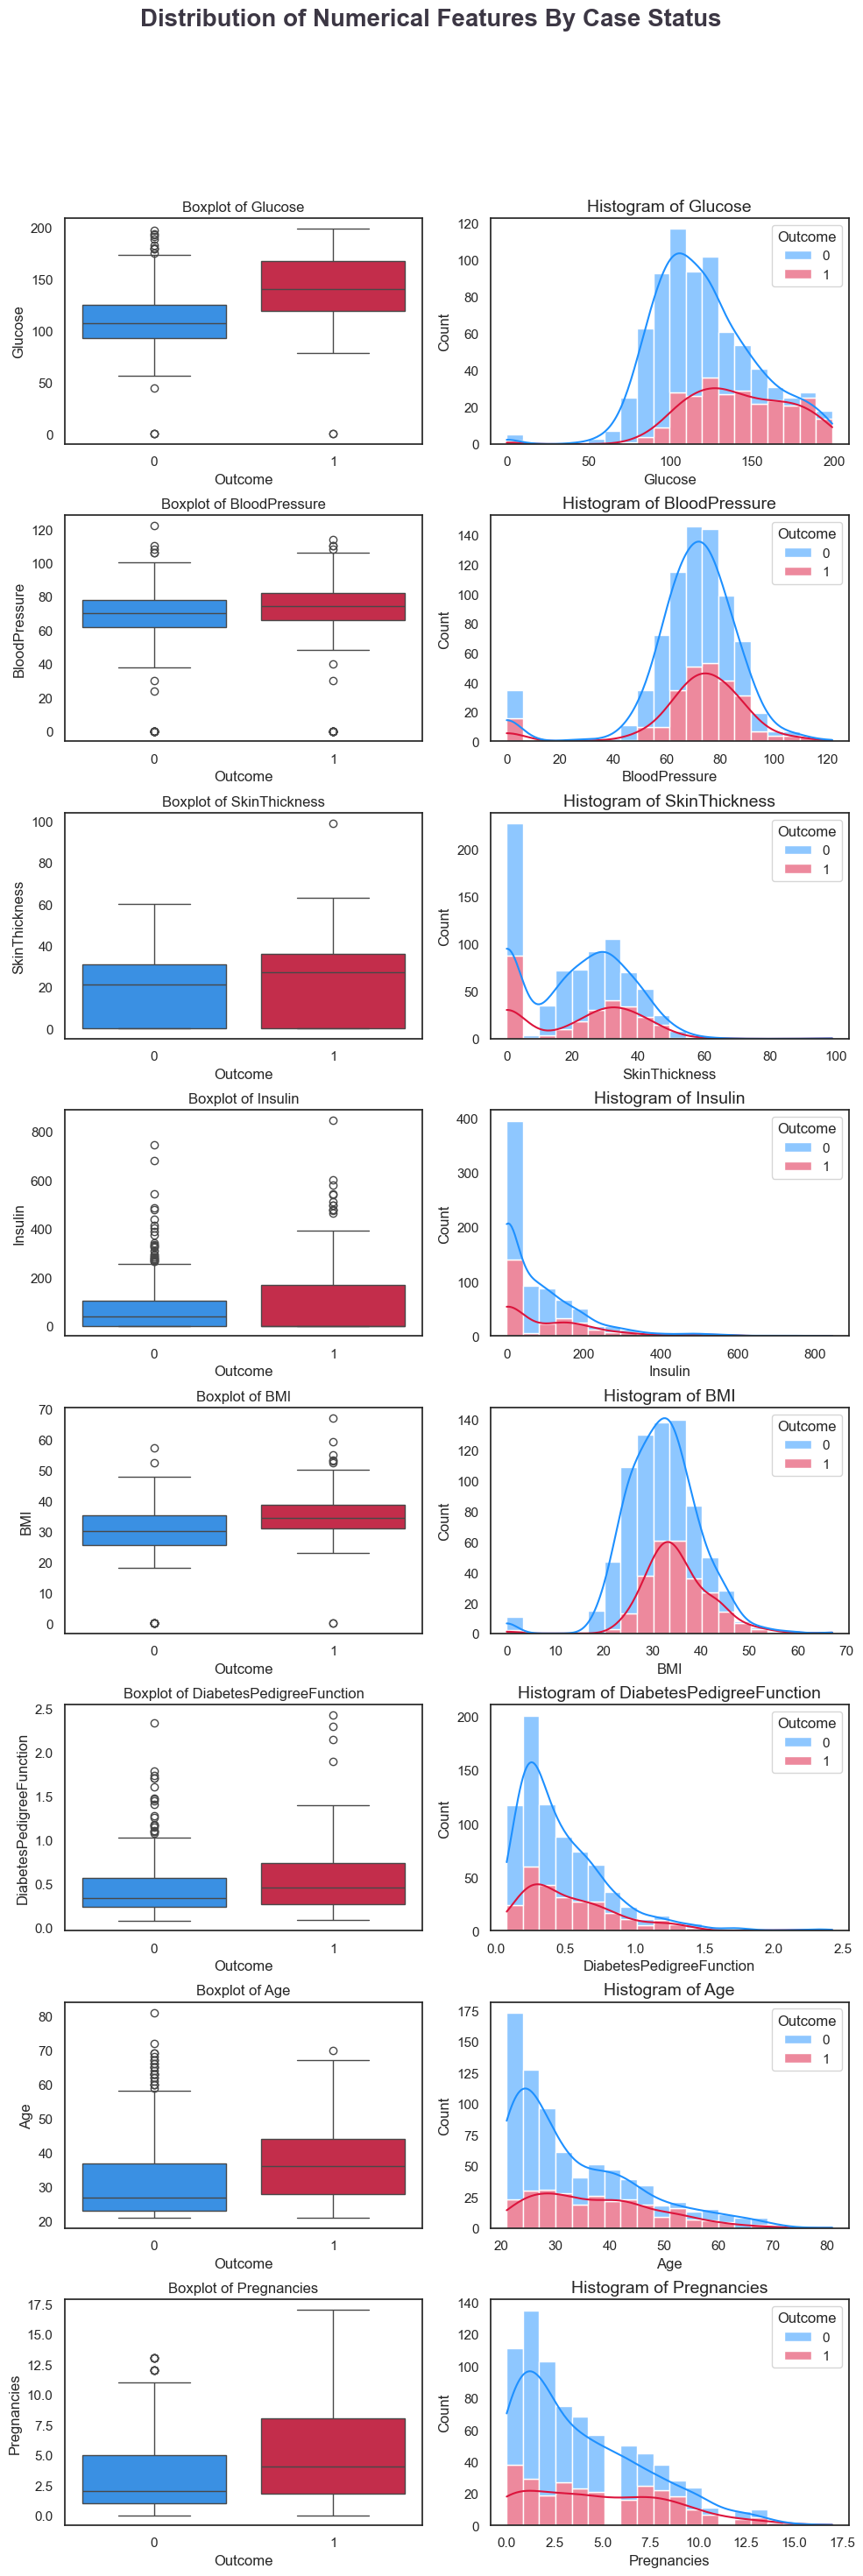

In [19]:
clr1 = ['#1E90FF', '#DC143C']
features = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age','Pregnancies']

fig, ax = plt.subplots(len(features), 2, figsize=(10, 30))
fig.suptitle('Distribution of Numerical Features By Case Status', color='#3C3744', 
             fontsize=20, fontweight='bold', ha='center')

for i, col in enumerate(features):   
    sns.boxplot(data=df, x='Outcome', y=col, hue='Outcome', palette=clr1, ax=ax[i, 0], legend=False)
    ax[i, 0].set_title(f'Boxplot of {col}', fontsize=12)
    
    sns.histplot(data=df, x=col, hue='Outcome', bins=20, kde=True, 
                 multiple='stack', palette=clr1, ax=ax[i, 1])
    ax[i, 1].set_title(f'Histogram of {col}', fontsize=14)

fig.tight_layout()
fig.subplots_adjust(top=0.90)
plt.show()

In [20]:
num_duplicates = df.duplicated().sum()
df_no_duplicates = df.drop_duplicates()
print(f"تعداد ردیف‌های تکراری: {num_duplicates}")

تعداد ردیف‌های تکراری: 0


In [21]:
for i in df.columns:
    print (i,len(df[df[i]=='?']))

Pregnancies 0
Glucose 0
BloodPressure 0
SkinThickness 0
Insulin 0
BMI 0
DiabetesPedigreeFunction 0
Age 0
Outcome 0


In [ ]:
cols_with_invalid_zeros  =   [  'Glucose'  ,   'BloodPressure'  ,  'SkinThickness'  ,  'Insulin'  ,   'BMI'  ]

zero_counts = {col: (df[col] == 0).sum() for col in cols_with_invalid_zeros}
df_zeros = pd.DataFrame(list(zero_counts.items()), columns=['Column', 'Zero Count'])
df_zeros


,Column,Zero Count
0,Glucose,5
1,BloodPressure,35
2,SkinThickness,227
3,Insulin,374
4,BMI,11


In [23]:
df[cols_with_invalid_zeros] = df[cols_with_invalid_zeros].replace(0, np.nan)
print("\nتعداد مقادیر ناموجود (NaN):")
df.isnull().sum()


تعداد مقادیر ناموجود (NaN):


Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [24]:
df['Glucose'] = df['Glucose'].fillna(df['Glucose'].mean())
df['SkinThickness'] = df['SkinThickness'].fillna(df['SkinThickness'].mean())
df['BMI'] = df['BMI'].fillna(df['BMI'].mean())

df['BloodPressure'] = df['BloodPressure'].fillna(df['BloodPressure'].median())
df['Insulin'] = df['Insulin'].fillna(df['Insulin'].median())

print("Remaining NaNs:\n", df.isna().sum())

Remaining NaNs:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [25]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00000,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.00000,168.0,43.1,2.288,33,1


In [27]:
def remove_outliers(df, columns):
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df[col] = df[col].apply(lambda x: x if lower_bound <= x <= upper_bound else np.nan)
        return df

cols_with_outliers = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'Age']
df_cleaned = remove_outliers(df.copy(), cols_with_outliers)
print("\nحذف مقادیر خارج از محدوده:")
print(df_cleaned.isnull().sum())


حذف مقادیر خارج از محدوده:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


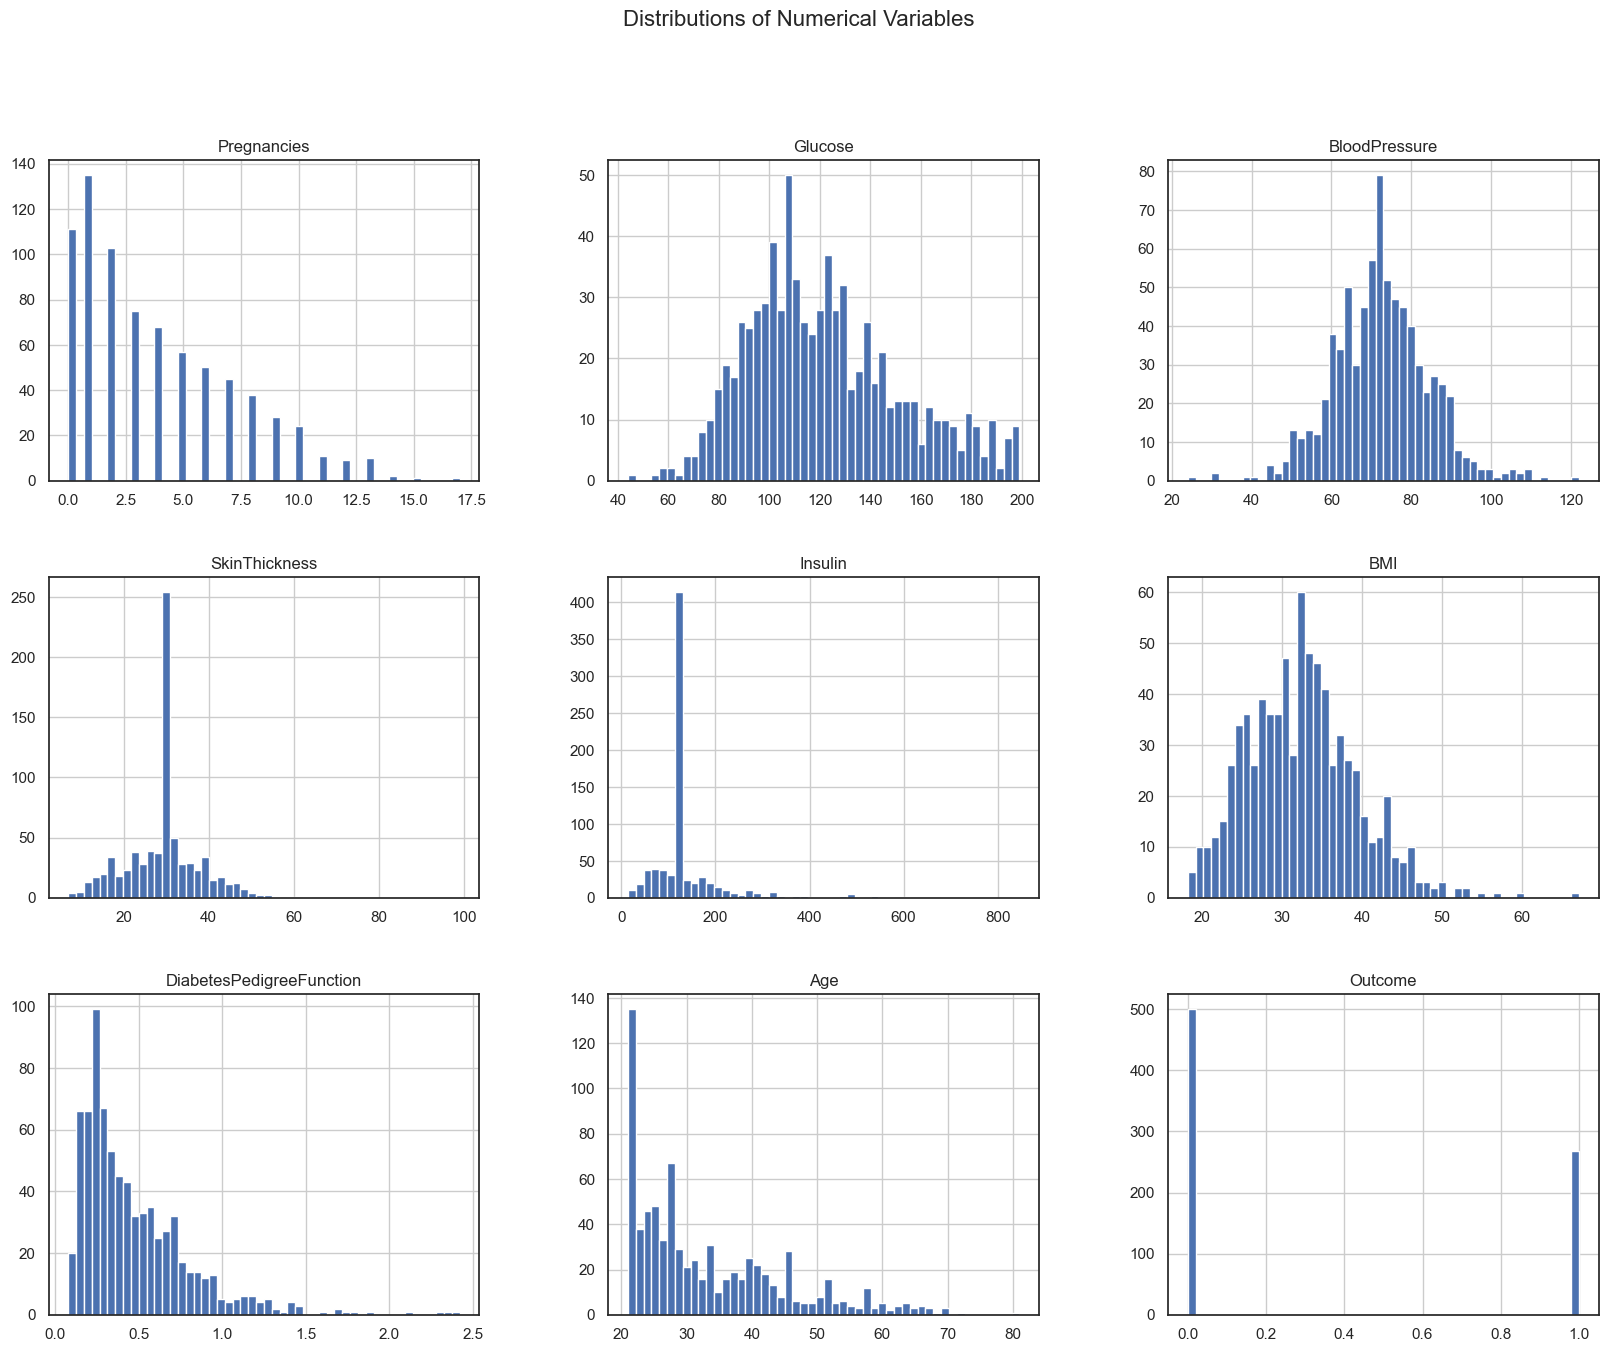

In [29]:
df_cleaned.hist(bins=50, figsize=(20, 15))
plt.suptitle("Distributions of Numerical Variables", fontsize=16)
plt.show()

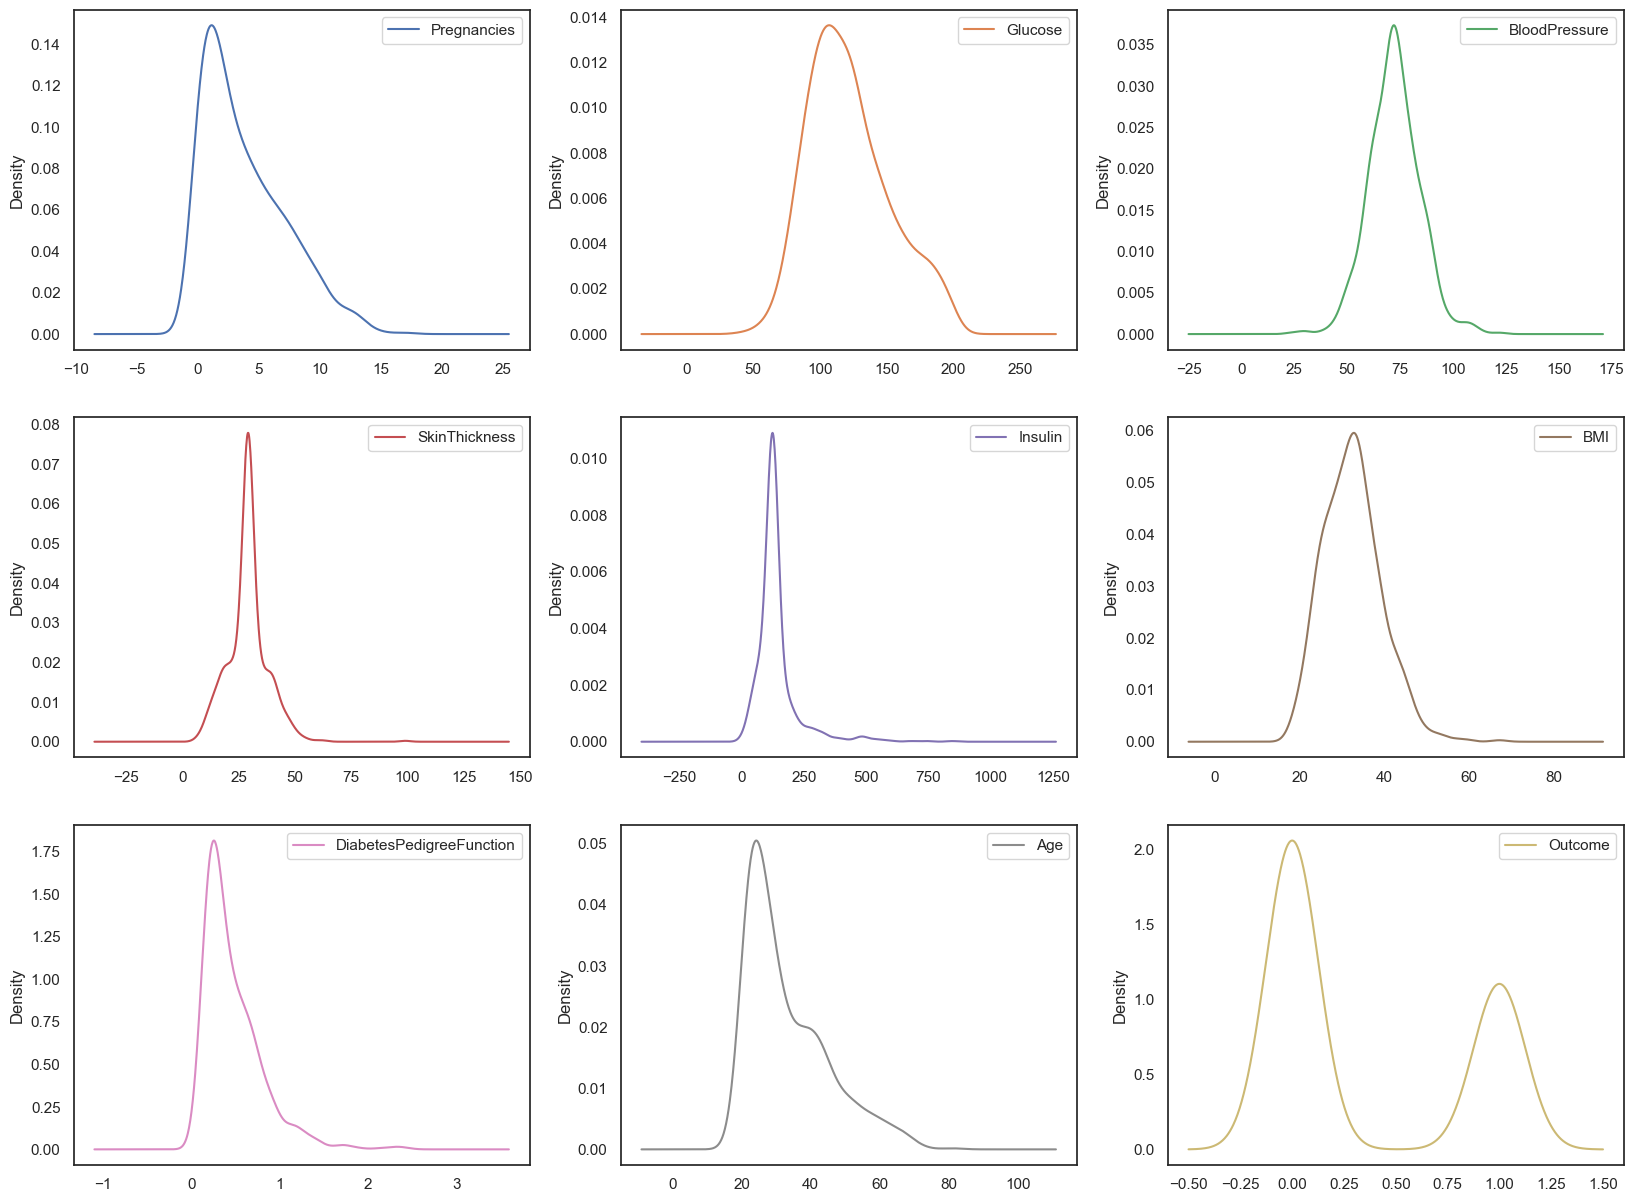

In [30]:
df_cleaned.plot(kind='density', subplots=True, layout=(3,3), figsize=(20, 15), sharex=False)
plt.show()

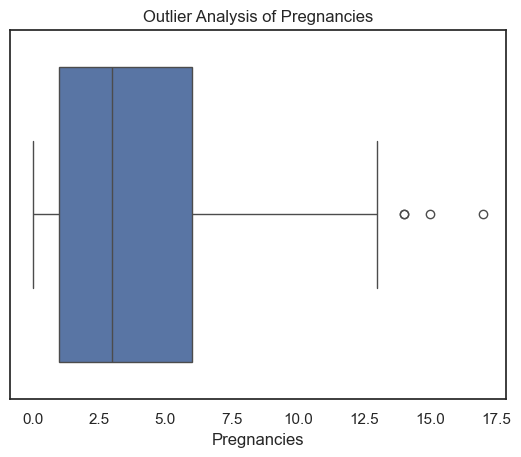

In [31]:
sns.boxplot(x='Pregnancies', data=df_cleaned)
plt.title("Outlier Analysis of Pregnancies")
plt.show()

In [32]:
Q1=df_cleaned["Pregnancies"].quantile(0.25)
Q3=df_cleaned["Pregnancies"].quantile(0.75)
IQR=Q3 - Q1

lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR

print(f"Outlier Boundaries: {lower_bound} with {upper_bound}")

Outlier Boundaries: -6.5 with 13.5


In [33]:
outliers=df_cleaned[df_cleaned["Pregnancies"]>upper_bound]
print(outliers[["Pregnancies", "Age", "Outcome"]])

     Pregnancies  Age  Outcome
88            15   43        1
159           17   47        1
298           14   46        1
455           14   38        1


In [34]:
outlier_indices = df[(df['Pregnancies'] < -6.5) | (df['Pregnancies'] > 13.5)].index

df_cleaned = df.drop(index=outlier_indices)

print(f"{len(outlier_indices)} ردیف به دلیل داشتن مقدار غیرمجاز در 'Pregnancies' حذف شد.")
print()
df_cleaned.shape


4 ردیف به دلیل داشتن مقدار غیرمجاز در 'Pregnancies' حذف شد.



(764, 9)

# Z_Score

In [35]:
df_cluster = df_cleaned.drop(columns=['Outcome'])
df_cluster

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.00000,125.0,33.6,0.627,50
1,1,85.0,66.0,29.00000,125.0,26.6,0.351,31
2,8,183.0,64.0,29.15342,125.0,23.3,0.672,32
3,1,89.0,66.0,23.00000,94.0,28.1,0.167,21
4,0,137.0,40.0,35.00000,168.0,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101.0,76.0,48.00000,180.0,32.9,0.171,63
764,2,122.0,70.0,27.00000,125.0,36.8,0.340,27
765,5,121.0,72.0,23.00000,112.0,26.2,0.245,30
766,1,126.0,60.0,29.15342,125.0,30.1,0.349,47


In [36]:
scaler = StandardScaler()

df_zcore = scaler.fit_transform(df_cluster)

In [37]:
pca_out = PCA()
pca_scores = pca_out.fit_transform(df_zcore)

pc_list = [f"PC{i}" for i in range(1, pca_scores.shape[1] + 1)]
df_pca = pd.DataFrame(pca_scores, columns=pc_list)

df_explained_variance_cumsum = pd.DataFrame(
    [np.cumsum(pca_out.explained_variance_ratio_)],
    columns=pc_list
)

In [38]:
df_explained_variance_cumsum

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
0,0.285009,0.473155,0.616179,0.73088,0.826316,0.894084,0.951912,1.0


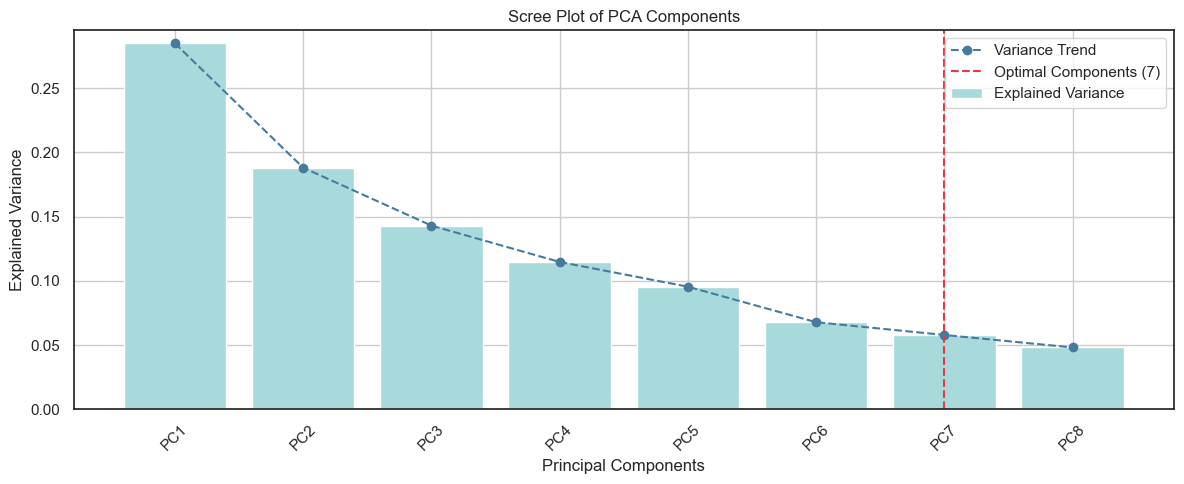

In [130]:
cumulative_variance = np.cumsum(pca_out.explained_variance_ratio_)
optimal_components = np.argmax(cumulative_variance >= 0.90) + 1

component_numbers = list(range(1, len(pc_list) + 1))

plt.figure(figsize=(12, 5))
plt.bar(component_numbers, pca_out.explained_variance_ratio_, color='#a8dadc', label='Explained Variance')
plt.plot(component_numbers, pca_out.explained_variance_ratio_, marker='o', linestyle='--', color='#457b9d', label='Variance Trend')
plt.axvline(x=optimal_components, color='#e63946', linestyle='--', label=f"Optimal Components ({optimal_components})")
plt.xticks(component_numbers, pc_list, rotation=45)
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance')
plt.title('Scree Plot of PCA Components')
plt.ylim(0, max(pca_out.explained_variance_ratio_) + 0.01)
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()

In [40]:
pca = PCA(n_components= 7)
X_pca = pca.fit_transform(df_zcore)

print("Transformed Data (PCA Features - 7 components):", X_pca)
print("Explained variance ratio:", pca.explained_variance_ratio_)



Transformed Data (PCA Features - 7 components): [[ 1.45933434  0.67901536  0.17165659 ... -0.43862948  0.82490441
  -0.31218259]
 [-1.49577401 -0.07309354 -0.23714992 ... -0.26683774 -0.33542186
  -0.93228282]
 [ 0.44701335  0.78659826  1.63106549 ... -0.40733532  1.49763319
   0.534438  ]
 ...
 [-0.86290179  0.90333708  0.21978268 ...  0.14774081  0.10885833
   0.23680575]
 [-0.37801488  0.21527488  0.40441604 ... -0.54611755  0.85733444
  -0.94006218]
 [-1.22765206 -0.65236527 -0.6007883  ... -0.04795933 -0.33909865
  -0.44343093]]
Explained variance ratio: [0.28500886 0.18814616 0.14302426 0.11470058 0.09543566 0.06776824
 0.05782848]


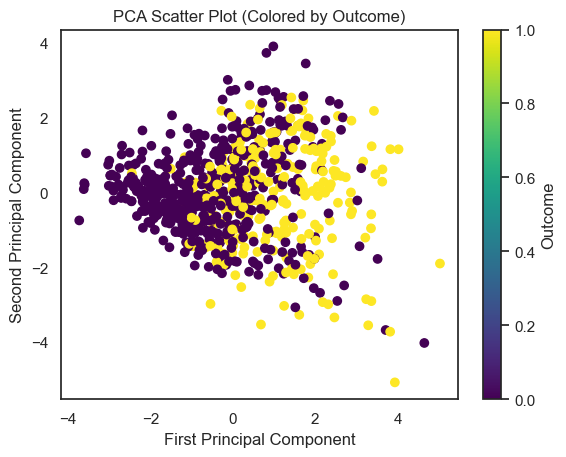

In [41]:
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df_cleaned['Outcome'].values, cmap='viridis')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA Scatter Plot (Colored by Outcome)')
plt.colorbar(label='Outcome')
plt.show()

# AgglomerativeClustering

In [42]:
clustering_single = AgglomerativeClustering(n_clusters=None, distance_threshold=3.0, linkage='single')
labels = clustering_single.fit_predict(X_pca)

## Single

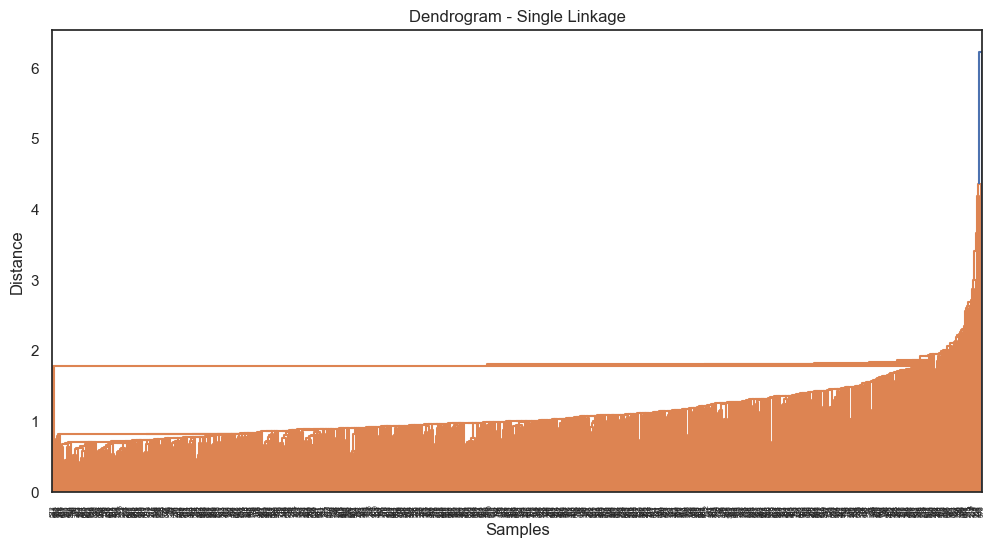

In [43]:
linked = linkage(X_pca, method='single')
plt.figure(figsize=(12, 6))
dendrogram(linked,
           orientation='top',
           distance_sort='descending',
           show_leaf_counts=False)
plt.title("Dendrogram - Single Linkage")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()

## Complete

In [44]:
clustering_complete = AgglomerativeClustering(n_clusters=None, distance_threshold=3.0, linkage='complete')
labels = clustering_complete.fit_predict(X_pca)

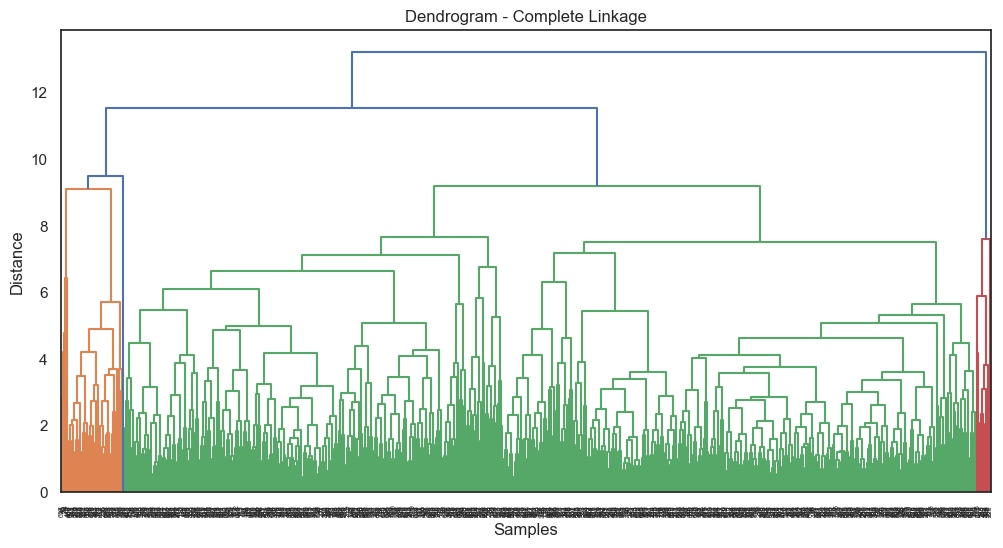

In [45]:
linked = linkage(X_pca, method='complete')
plt.figure(figsize=(12, 6))
dendrogram(linked,
           orientation='top',
           distance_sort='descending',
           show_leaf_counts=False)
plt.title("Dendrogram - Complete Linkage")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()

## Average

In [46]:
clustering_average = AgglomerativeClustering(n_clusters=None, distance_threshold=3.0, linkage='average')
labels = clustering_average.fit_predict(X_pca)

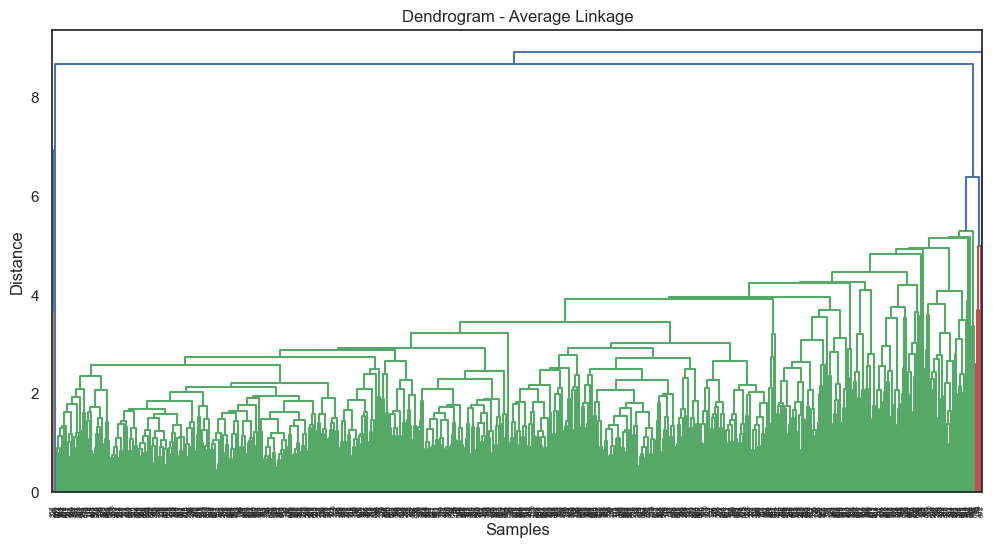

In [47]:
linked = linkage(X_pca, method='average')
plt.figure(figsize=(12, 6))
dendrogram(linked,
           orientation='top',
           distance_sort='descending',
           show_leaf_counts=False)
plt.title("Dendrogram - Average Linkage")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()

## Ward

In [48]:
clustering_ward = AgglomerativeClustering(n_clusters=None, distance_threshold=3.0, linkage='ward')
labels = clustering_ward.fit_predict(X_pca)

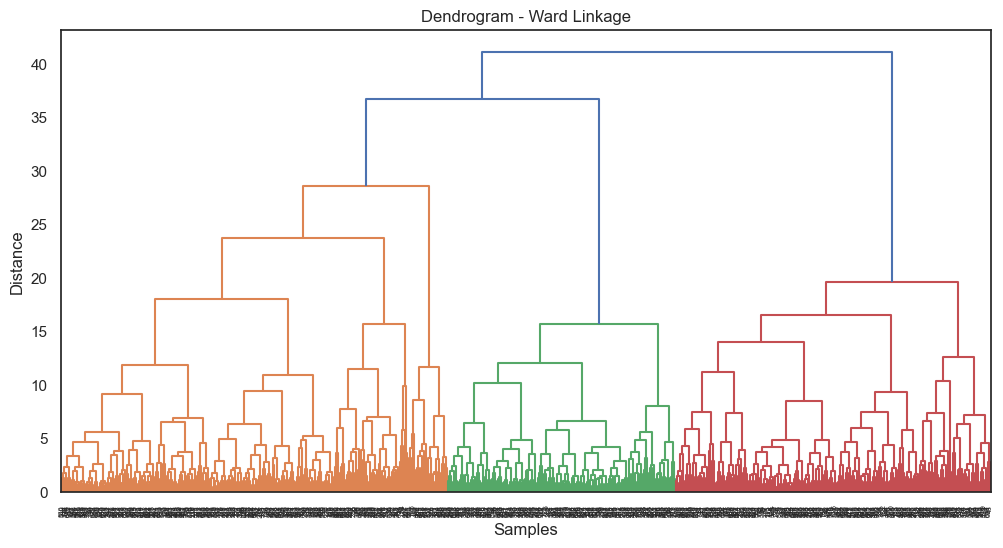

In [49]:
linked = linkage(X_pca, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(linked,
           orientation='top',
           distance_sort='descending',
           show_leaf_counts=False)
plt.title("Dendrogram - Ward Linkage")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()

## Centroid

In [ ]:
clustering_centroid = AgglomerativeClustering(n_clusters=None, distance_threshold=3.0, linkage='centroid')
labels = clustering_centroid.fit_predict(X_pca)

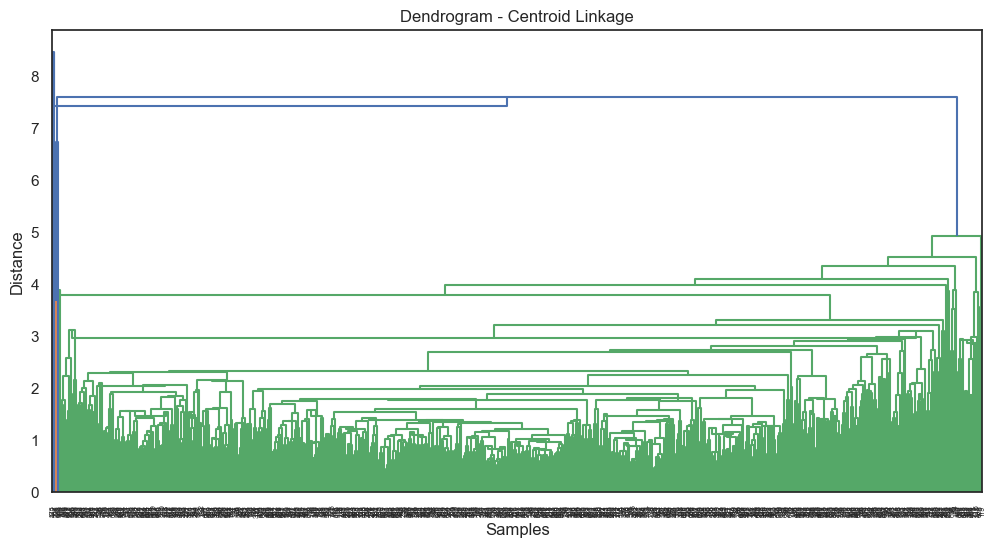

In [50]:
Z = linkage(X_pca, method='centroid')
labels = fcluster(Z, t=2, criterion='maxclust')

plt.figure(figsize=(12, 6))
dendrogram(Z,
           orientation='top',
           distance_sort='descending',
           show_leaf_counts=False)
plt.title("Dendrogram - Centroid Linkage")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()

# DBSCAN

In [99]:
sil = []

algorithm = ['auto','ball_tree','kd_tree','brute']

for i in np.arange(0.4, 7, 0.01):
    for j in np.arange(2,11,1):
        for a in algorithm:
            db = DBSCAN(eps=i, min_samples=j,algorithm=a).fit(X_pca)
            labels_db = db.labels_

            n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
            cluster_centers = []
            if n_clusters > 0:  
                for label in set(labels_db) - {-1}:  
                    cluster_points = X_pca[labels_db == label]
                    center = np.mean(cluster_points, axis=0)
                    cluster_centers.append(center)
                cluster_centers = np.array(cluster_centers) if cluster_centers else None
            else:
                cluster_centers = None

            if len(set(labels_db)) > 1:
                sil_score = silhouette_score(X_pca,labels_db)
                sil.append([i,j,a,sil_score,n_clusters])
            else:
                sil.append([i,j,a,None])


sil = pd.DataFrame(sil)


In [100]:
sil = sil.sort_values(by=3,ascending = False)
sil

,0,1,2,3,4
14505,4.42,10,ball_tree,0.604176,1.0
14610,4.45,9,kd_tree,0.604176,1.0
14577,4.44,10,ball_tree,0.604176,1.0
14576,4.44,10,auto,0.604176,1.0
14611,4.45,9,brute,0.604176,1.0
...,...,...,...,...,...
23755,6.99,9,brute,NaN,NaN
23756,6.99,10,auto,NaN,NaN
23757,6.99,10,ball_tree,NaN,NaN
23758,6.99,10,kd_tree,NaN,NaN


In [101]:
db = DBSCAN(eps=4.42, min_samples=10,algorithm='ball_tree')
db.fit(X_pca)

DBSCAN(algorithm='ball_tree', eps=4.42, min_samples=10)

In [102]:
labels_db

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [ ]:
core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True
labels = db.labels_

n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print('Estimated number of clusters: %d' % n_clusters_)
print('Estimated number of noise points: %d' % n_noise_)

Estimated number of clusters: 1
Estimated number of noise points: 2


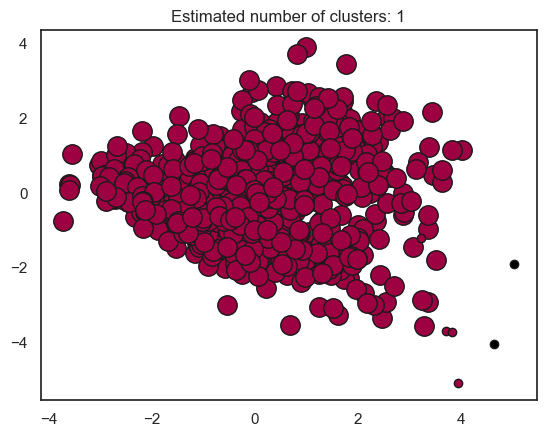

In [ ]:
unique_labels = set(labels)
colors = [plt.cm.Spectral(each)
          for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
 
        col = [0, 0, 0, 1]

    class_member_mask = (labels == k)

    xy = X_pca[class_member_mask & core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=14)

    xy = X_pca[class_member_mask & ~core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=6)

plt.title('Estimated number of clusters: %d' % n_clusters_)
plt.show()

In [105]:

for k in unique_labels:
    if k == -1:
        continue
    mask = (labels == k)
    cluster_center = X_pca[mask].mean(axis=0)
    print(f"Cluster {k} center:", cluster_center)


Cluster 0 center: [-0.01270678  0.00778176 -0.005249   -0.00293987  0.00456052 -0.00074126
  0.00652317]


In [ ]:
true_labels = df_cleaned['Outcome'].values

def match_clusters_to_labels(true_labels, labels_db):

    contingency_matrix = np.zeros((len(set(true_labels)), len(set(labels_db))))
    for i in range(len(true_labels)):
        contingency_matrix[true_labels[i]][labels_db[i]] += 1

    row_ind, col_ind = linear_sum_assignment(-contingency_matrix)
    mapping = {col: row for row, col in zip(row_ind, col_ind)}
    pred_mapped = [mapping[c] for c in labels_db]
    return pred_mapped


mask = labels_db != -1
labels_db_filtered = labels_db[mask]
true_labels_filtered = true_labels[mask]
y_pred_matched = match_clusters_to_labels(true_labels_filtered, labels_db_filtered)

print("Accuracy:", accuracy_score(true_labels_filtered ,y_pred_matched))
print("ARI:", adjusted_rand_score(true_labels_filtered, labels_db_filtered))
print("NMI:", normalized_mutual_info_score(true_labels_filtered, labels_db_filtered))
print("FMI:", fowlkes_mallows_score(true_labels_filtered, labels_db_filtered))



Accuracy: 0.6544502617801047
ARI: 0.0
NMI: 0.0
FMI: 0.7396735684856245


In [109]:
if n_clusters > 1:
    print("Davies-Bouldin Index:", davies_bouldin_score(X_pca, labels_db))
    print("Calinski-Harabasz Index:", calinski_harabasz_score(X_pca, labels_db))
else:
    print("⛔ فقط یک خوشه شناسایی شده — معیارهای درونی قابل محاسبه نیستند.")


⛔ فقط یک خوشه شناسایی شده — معیارهای درونی قابل محاسبه نیستند.


# SOM

In [58]:

q_e = []

learning_rates = [0.01, 0.05]
neighborhood_function = ['gaussian', 'triangle']
topology = ['rectangular']
activation_distance = ['euclidean', 'manhattan']
random_seed = [42]

for i in range(3, 9, 2):
    for j in range(3, 9, 2):
        for k in learning_rates:
            for n in neighborhood_function:
                for t in topology:
                    for a in activation_distance:
                        for r in random_seed:
                            for f in range(2000, 10001, 2000):
                                som = MiniSom(x=i, y=j, input_len=X_pca.shape[1], sigma=1.0, learning_rate=k,
                                             neighborhood_function=n, topology=t, random_seed=r)
                                som.train_batch(X_pca, f, verbose=False)
                                q_e.append(
                                    [i, j, k, n, t, a, r, f, (som.topographic_error(X_pca) + som.quantization_error(X_pca)) / 2]
                                )


In [ ]:
q_e = pd.DataFrame(q_e)

q_e = q_e.sort_values(by=8, ascending=True)
q_e


,0,1,2,3,4,5,6,7,8
344,7,7,0.05,gaussian,rectangular,euclidean,42,10000,0.773848
349,7,7,0.05,gaussian,rectangular,manhattan,42,10000,0.773848
341,7,7,0.05,gaussian,rectangular,euclidean,42,4000,0.795163
346,7,7,0.05,gaussian,rectangular,manhattan,42,4000,0.795163
348,7,7,0.05,gaussian,rectangular,manhattan,42,8000,0.798533
...,...,...,...,...,...,...,...,...,...
215,5,7,0.01,triangle,rectangular,manhattan,42,2000,1.344221
95,3,7,0.01,triangle,rectangular,manhattan,42,2000,1.362013
90,3,7,0.01,triangle,rectangular,euclidean,42,2000,1.362013
335,7,7,0.01,triangle,rectangular,manhattan,42,2000,1.364116


In [60]:
som_shape = (2,1)
som = MiniSom(
    x=som_shape[0],
    y=som_shape[1],
    input_len=X_pca.shape[1],
    sigma=1.0,
    learning_rate=0.05,
    neighborhood_function='gaussian',
    topology='rectangular',
    activation_distance='euclidean',
    random_seed=42
)

som.train_batch(X_pca,10000,verbose=True)          


 [ 10000 / 10000 ] 100% - 0:00:00 left 
 quantization error: 2.267871088443609


In [61]:
print('\nsom topologic_error=>',som.topographic_error(X_pca))
print('\nsom quantization_error=>',som.quantization_error(X_pca))
print('\nsom average topologic and quantization=>',(som.topographic_error(X_pca) + som.quantization_error(X_pca))/2)



som topologic_error=> 0.0

som quantization_error=> 2.267871088443609

som average topologic and quantization=> 1.1339355442218044


In [92]:
winner_coordinates = np.array([som.winner(x) for x in X_pca]).T

cluster_index = np.ravel_multi_index(winner_coordinates, som_shape)
labels_som = cluster_index
labels_som

array([1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1,
       1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1,
       0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1,

In [63]:
std2 = []
centroids = []

for i in range(som_shape[0] * som_shape[1]):
    row = math.floor(i / som_shape[1])
    col = i % som_shape[1]
    
    weight_vector = som.get_weights()[row, col]
    st_d = ((X_pca[cluster_index == i] - weight_vector) ** 2).sum(1)

    if st_d.any() != 0:
        centroids.append(weight_vector)

centroids = np.array(centroids)
centroids

array([[-1.04056618, -0.24125558, -0.00208567, -0.04451826, -0.12942867,
        -0.0388349 , -0.01087829],
       [ 1.35126482,  0.41071428,  0.01864955,  0.12613104,  0.007779  ,
        -0.01320157, -0.01466861]])

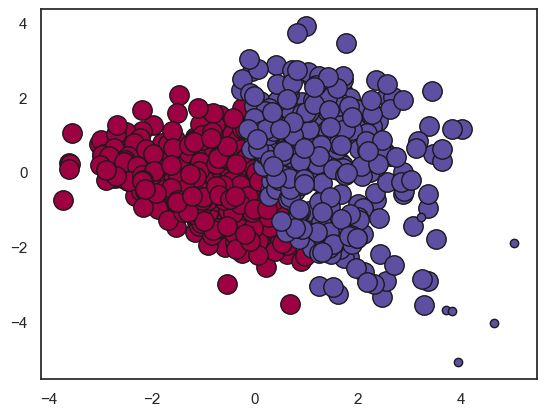

In [ ]:
unique_labels = set(labels)
colors = [plt.cm.Spectral(each)
          for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:

        col = [0, 0, 0, 1]

    class_member_mask = (labels == k)

    xy = X_pca[class_member_mask & core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=14)

    xy = X_pca[class_member_mask & ~core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=6)

plt.show()

In [65]:
print('\nsilhouette_score=>',silhouette_score(X_pca,cluster_index))


silhouette_score=> 0.20936951988418395


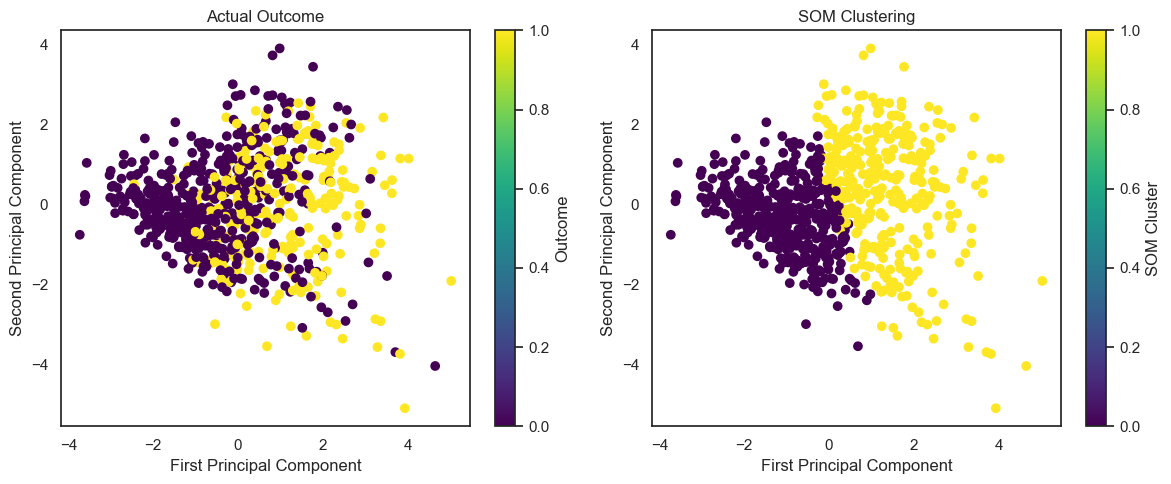

In [ ]:

fig, axs = plt.subplots(1, 2, figsize=(12,5))


sc0 = axs[0].scatter(X_pca[:, 0], X_pca[:, 1], c=df_cleaned["Outcome"].values, cmap='viridis')
axs[0].set_title("Actual Outcome")
axs[0].set_xlabel("First Principal Component")
axs[0].set_ylabel("Second Principal Component")
fig.colorbar(sc0, ax=axs[0], label="Outcome")


sc1 = axs[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis')
axs[1].set_title("SOM Clustering")
axs[1].set_xlabel("First Principal Component")
axs[1].set_ylabel("Second Principal Component")
fig.colorbar(sc1, ax=axs[1], label="SOM Cluster")

plt.tight_layout()
plt.show()


In [ ]:
def match_clusters_to_labels(true_labels, labels_som):

    contingency_matrix = np.zeros((len(set(true_labels)), len(set(labels_som))))
    for i in range(len(true_labels)):
        contingency_matrix[true_labels[i]][labels_som[i]] += 1

    row_ind, col_ind = linear_sum_assignment(-contingency_matrix)
    mapping = {col: row for row, col in zip(row_ind, col_ind)}
    pred_mapped = [mapping[c] for c in labels_som]
    return pred_mapped


y_pred_matched = match_clusters_to_labels(true_labels, labels_som)

print("Accuracy:", accuracy_score(true_labels, y_pred_matched))
print("ARI:", adjusted_rand_score(true_labels, labels_som))
print("NMI:", normalized_mutual_info_score(true_labels, labels_som))
print("FMI:", fowlkes_mallows_score(true_labels, labels_som))

Accuracy: 0.7081151832460733
ARI: 0.17097946655171367
NMI: 0.12194683142206386
FMI: 0.6079761753392628


In [ ]:
print("Davies-Bouldin Index:", davies_bouldin_score(X_pca, labels_som))
print("Calinski-Harabasz Index:", calinski_harabasz_score(X_pca, labels_som))

Davies-Bouldin Index: 1.8607279951815625
Calinski-Harabasz Index: 188.96795832046422


# K-means

In [67]:
km = KMeans (n_clusters=2, random_state=0, n_init="auto")
km.fit(X_pca)

KMeans(n_clusters=2, random_state=0)

In [90]:
labels_km = km.labels_
labels_km

array([1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1,
       1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1,
       1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1,
       0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1,

In [69]:
km.inertia_

4657.294405744618

In [70]:
print('\nsilhouette_score=>',silhouette_score(X_pca,km.labels_))


silhouette_score=> 0.2083504152582515


In [71]:
centroids_kmeans = km.cluster_centers_
print("K-Means Cluster Centers:")
print(centroids_kmeans)

K-Means Cluster Centers:
[[-1.06258218 -0.26162204 -0.02057542  0.00385517  0.02021763 -0.01483813
  -0.02246635]
 [ 1.34635783  0.33149142  0.02607034 -0.00488475 -0.025617    0.01880084
   0.02846627]]


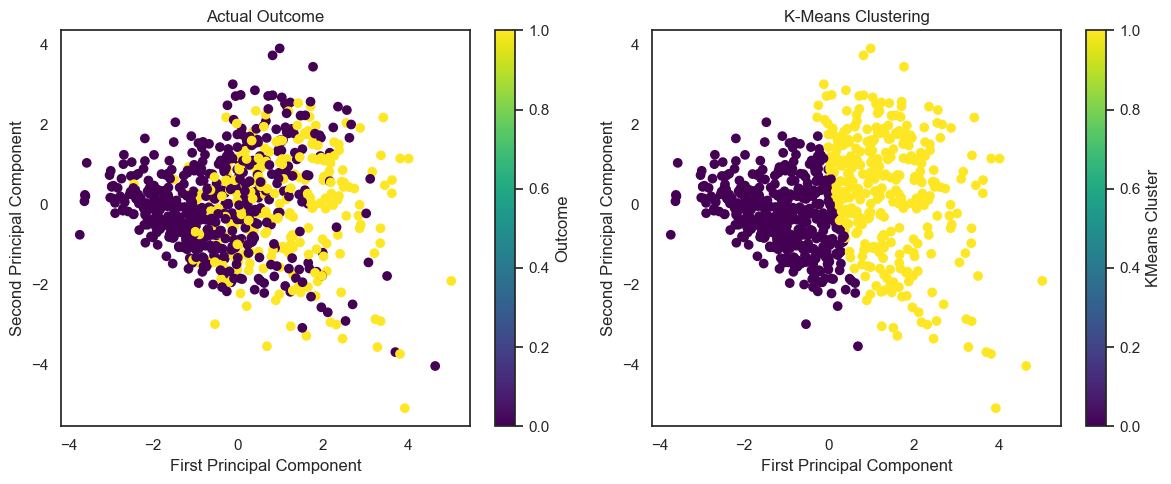

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))


sc0 = axs[0].scatter(X_pca[:, 0], X_pca[:, 1], c=df_cleaned["Outcome"].values, cmap='viridis')
axs[0].set_title("Actual Outcome")
axs[0].set_xlabel("First Principal Component")
axs[0].set_ylabel("Second Principal Component")
fig.colorbar(sc0, ax=axs[0], label="Outcome")


sc1 = axs[1].scatter(X_pca[:, 0], X_pca[:, 1], c=km.labels_, cmap='viridis')
axs[1].set_title("K-Means Clustering")
axs[1].set_xlabel("First Principal Component")
axs[1].set_ylabel("Second Principal Component")
fig.colorbar(sc1, ax=axs[1], label="KMeans Cluster")

plt.tight_layout()
plt.show()


In [ ]:
def match_clusters_to_labels(true_labels,labels_km ):

    contingency_matrix = np.zeros((len(set(true_labels)), len(set(labels_km))))
    for i in range(len(true_labels)):
        contingency_matrix[true_labels[i]][labels_km[i]] += 1

    row_ind, col_ind = linear_sum_assignment(-contingency_matrix)
    mapping = {col: row for row, col in zip(row_ind, col_ind)}
    pred_mapped = [mapping[c] for c in labels_km]
    return pred_mapped

y_pred_matched = match_clusters_to_labels(true_labels, labels_km)

print("Accuracy:", accuracy_score(true_labels, y_pred_matched))
print("ARI:", adjusted_rand_score(true_labels, labels_km))
print("NMI:", normalized_mutual_info_score(true_labels, labels_km))
print("FMI:", fowlkes_mallows_score(true_labels, labels_km))

Accuracy: 0.7094240837696335
ARI: 0.17342042413036593
NMI: 0.12615873928780408
FMI: 0.6084578793020045


In [114]:
print("Davies-Bouldin Index:", davies_bouldin_score(X_pca, labels_km))
print("Calinski-Harabasz Index:", calinski_harabasz_score(X_pca, labels_km))

Davies-Bouldin Index: 1.8567138767677775
Calinski-Harabasz Index: 189.93270039124974


# Fuzzy

In [85]:
data_fcm = X_pca.T

cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    data_fcm, c=2, m=2, error=0.005, maxiter=1000, init=None
)


In [86]:
labels_cms = pairwise_distances_argmin(X_pca, cntr)

print("Cluster labels for each sample:")
print(labels_cms)

Cluster labels for each sample:
[1 0 1 0 0 0 0 1 1 1 1 1 1 1 1 0 1 0 0 0 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 0 1
 1 0 1 0 1 1 1 1 1 0 0 1 0 0 0 0 1 1 0 1 1 1 0 0 1 0 0 1 0 1 1 0 1 0 0 1 1
 0 0 1 0 0 0 0 0 0 0 1 0 1 0 0 0 0 1 1 0 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 1 1
 0 0 1 1 1 0 0 0 1 0 0 1 0 0 1 0 1 1 0 1 1 1 0 0 0 0 0 1 1 1 0 1 0 0 1 0 1
 0 1 0 1 1 1 1 0 0 0 1 1 1 0 1 1 0 0 0 0 1 1 0 0 0 1 1 1 1 1 0 0 0 0 1 1 1
 1 1 1 0 1 1 1 0 1 0 0 0 0 0 1 0 0 1 0 1 1 0 1 0 1 1 0 1 1 0 1 0 1 1 1 1 1
 0 0 0 0 1 0 1 1 0 0 0 1 1 1 1 0 0 0 0 0 1 1 1 1 1 0 1 0 0 0 1 0 0 0 0 1 1
 0 0 1 0 0 0 1 0 0 1 0 0 0 1 0 0 0 1 0 0 1 1 1 1 1 1 1 0 1 0 0 1 0 1 1 1 0
 1 0 0 1 1 0 1 1 0 0 0 0 0 0 0 1 0 0 1 0 1 0 0 0 1 0 0 0 1 1 0 1 0 1 1 0 1
 1 1 1 1 0 0 0 1 1 1 0 0 0 1 0 1 0 0 0 1 0 1 1 1 1 1 1 1 1 0 0 0 0 1 1 0 0
 0 0 1 0 0 1 1 0 0 0 0 0 0 1 1 1 0 0 1 0 0 1 0 0 0 0 1 0 1 1 1 1 0 1 0 1 1
 1 0 1 0 0 1 0 1 0 0 1 0 0 0 1 1 0 1 1 0 0 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1 0
 0 0 0 0 0 0 1 0 1 0 1 1 1 0 1 0 1 0 0 0 1 1 1 0 0 1 0 1 1 0 1 1 1 1

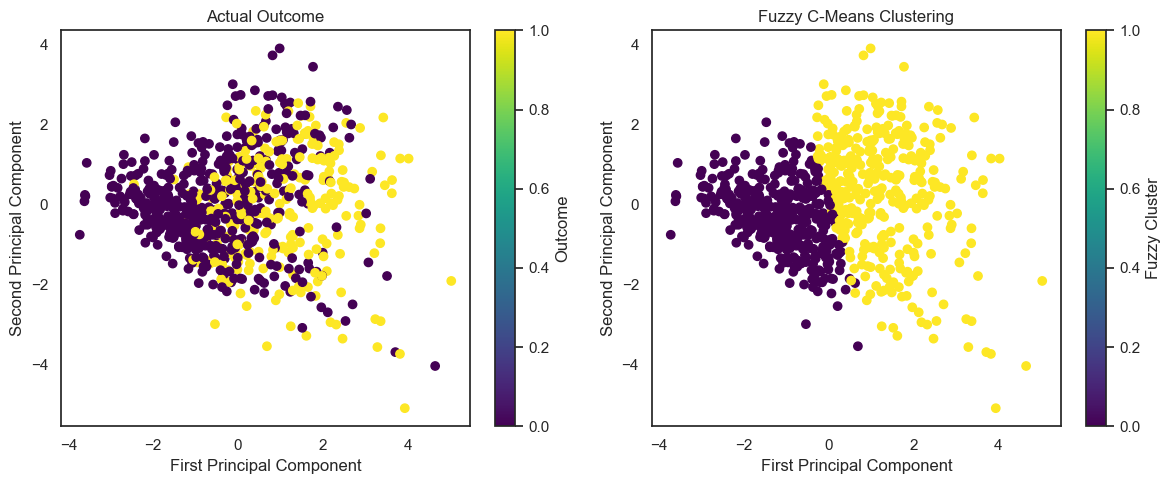

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))


sc0 = axs[0].scatter(X_pca[:, 0], X_pca[:, 1], c=df_cleaned["Outcome"].values, cmap='viridis')
axs[0].set_title("Actual Outcome")
axs[0].set_xlabel("First Principal Component")
axs[0].set_ylabel("Second Principal Component")
fig.colorbar(sc0, ax=axs[0], label="Outcome")

sc1 = axs[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_cms, cmap='viridis')
axs[1].set_title("Fuzzy C-Means Clustering")
axs[1].set_xlabel("First Principal Component")
axs[1].set_ylabel("Second Principal Component")
fig.colorbar(sc1, ax=axs[1], label="Fuzzy Cluster")

plt.tight_layout()
plt.show()

In [88]:
print("Shape of cluster centers:", cntr.shape)
print("Fuzzy C-Means Cluster Centers:")
print(cntr)


Shape of cluster centers: (2, 7)
Fuzzy C-Means Cluster Centers:
[[-0.63607589 -0.16843139  0.00475724 -0.03816206  0.00103269 -0.02169919
  -0.01777889]
 [ 0.69265059  0.2237371  -0.01919569  0.03186275 -0.00532174  0.03415974
   0.02786763]]


In [ ]:
def match_clusters_to_labels(true_labels, labels_cms):

    contingency_matrix = np.zeros((len(set(true_labels)), len(set(labels_cms))))
    for i in range(len(true_labels)):
        contingency_matrix[true_labels[i]][labels_cms[i]] += 1

    row_ind, col_ind = linear_sum_assignment(-contingency_matrix)
    mapping = {col: row for row, col in zip(row_ind, col_ind)}
    pred_mapped = [mapping[c] for c in labels_cms]
    return pred_mapped

y_pred_matched = match_clusters_to_labels(true_labels, labels_cms)

print("Accuracy:", accuracy_score(true_labels, y_pred_matched))
print("ARI:", adjusted_rand_score(true_labels, labels_cms))
print("NMI:", normalized_mutual_info_score(true_labels, labels_cms))
print("FMI:", fowlkes_mallows_score(true_labels, labels_cms))

Accuracy: 0.6897905759162304
ARI: 0.14290575775552025
NMI: 0.11425247357348103
FMI: 0.5914836517081874


In [115]:
print("Davies-Bouldin Index:", davies_bouldin_score(X_pca, labels_cms))
print("Calinski-Harabasz Index:", calinski_harabasz_score(X_pca, labels_cms))

Davies-Bouldin Index: 1.8476154549721397
Calinski-Harabasz Index: 189.64907928294832


# PSO

In [ ]:

n_clusters = 2
n_particles =10
n_iterations = 30
n_features = X_pca.shape[1]
dimensions = n_clusters * n_features
v_max = 0.1


def compute_cost(centroids_flat, data, n_clusters):
    centroids = centroids_flat.reshape(n_clusters, -1)
    labels = pairwise_distances_argmin(data, centroids)
    cost = 0
    for i in range(len(data)):
        cost += np.linalg.norm(data[i] - centroids[labels[i]]) ** 2
    return cost

def run_pso_experiment(w, personal_c, social_c):

    low = np.tile(np.min(X_pca, axis=0), n_clusters)
    high = np.tile(np.max(X_pca, axis=0), n_clusters)
    particles = np.random.uniform(low=low, high=high, size=(n_particles, dimensions))
    velocities = np.random.uniform(-v_max, v_max, size=(n_particles, dimensions))
    pbest_positions = particles.copy()
    pbest_scores = np.array([compute_cost(p, X_pca, n_clusters) for p in particles])
    gbest_index = np.argmin(pbest_scores)
    gbest_position = pbest_positions[gbest_index].copy()
    gbest_score = pbest_scores[gbest_index]

    for iter in range(n_iterations):
        for i in range(n_particles):
            r1 = np.random.rand(dimensions)
            r2 = np.random.rand(dimensions)

            velocities[i] = (
                w * velocities[i]
                + personal_c * r1 * (pbest_positions[i] - particles[i])
                + social_c * r2 * (gbest_position - particles[i])
            )
            velocities[i] = np.clip(velocities[i], -v_max, v_max)

            particles[i] += velocities[i]

            particles[i] = np.clip(particles[i], low, high)

            cost = compute_cost(particles[i], X_pca, n_clusters)

            if cost < pbest_scores[i]:
                pbest_scores[i] = cost
                pbest_positions[i] = particles[i].copy()

            if cost < gbest_score:
                gbest_score = cost
                gbest_position = particles[i].copy()

    print(f"w={w}, c1={personal_c}, c2={social_c} => Best Cost: {gbest_score:.4f}")
    return gbest_score, (w, personal_c, social_c)


w_values = [0.6, 0.7, 0.8, 0.9]
c1_values = [1.5, 1.7, 2.5]
c2_values = [1.5, 1.7, 2.5]

best_score = float('inf')
best_params = None

for w in w_values:
    for c1 in c1_values:
        for c2 in c2_values:
            score, params = run_pso_experiment(w, c1, c2)
            if score < best_score:
                best_score = score
                best_params = params

print("\n=== بهترین پارامترها ===")
print(f"w={best_params[0]}, c1={best_params[1]}, c2={best_params[2]}")
print(f"Best Cost: {best_score:.4f}")


w=0.6, c1=1.5, c2=1.5 => Best Cost: 8984.7016
w=0.6, c1=1.5, c2=1.7 => Best Cost: 7768.0965
w=0.6, c1=1.5, c2=2.5 => Best Cost: 6786.7700
w=0.6, c1=1.7, c2=1.5 => Best Cost: 7199.0645
w=0.6, c1=1.7, c2=1.7 => Best Cost: 7261.2653
w=0.6, c1=1.7, c2=2.5 => Best Cost: 6478.9315
w=0.6, c1=2.5, c2=1.5 => Best Cost: 7116.6674
w=0.6, c1=2.5, c2=1.7 => Best Cost: 5848.0013
w=0.6, c1=2.5, c2=2.5 => Best Cost: 7362.7953
w=0.7, c1=1.5, c2=1.5 => Best Cost: 8139.3621
w=0.7, c1=1.5, c2=1.7 => Best Cost: 6945.2400
w=0.7, c1=1.5, c2=2.5 => Best Cost: 7005.4047
w=0.7, c1=1.7, c2=1.5 => Best Cost: 6644.9988
w=0.7, c1=1.7, c2=1.7 => Best Cost: 5682.5839
w=0.7, c1=1.7, c2=2.5 => Best Cost: 6703.1041
w=0.7, c1=2.5, c2=1.5 => Best Cost: 7523.1462
w=0.7, c1=2.5, c2=1.7 => Best Cost: 7408.1988
w=0.7, c1=2.5, c2=2.5 => Best Cost: 7326.1214
w=0.8, c1=1.5, c2=1.5 => Best Cost: 7519.0005
w=0.8, c1=1.5, c2=1.7 => Best Cost: 8464.9262
w=0.8, c1=1.5, c2=2.5 => Best Cost: 6027.5141
w=0.8, c1=1.7, c2=1.5 => Best Cost

Iteration 1, Best Cost: 7905.004476
Iteration 2, Best Cost: 6458.420229
Iteration 3, Best Cost: 6458.420229
Iteration 4, Best Cost: 6458.420229
Iteration 5, Best Cost: 6133.825844
Iteration 6, Best Cost: 6133.825844
Iteration 7, Best Cost: 6133.825844
Iteration 8, Best Cost: 5542.195075
Iteration 9, Best Cost: 5542.195075
Iteration 10, Best Cost: 5542.195075
Iteration 11, Best Cost: 5542.195075
Iteration 12, Best Cost: 5542.195075
Iteration 13, Best Cost: 5542.195075
Iteration 14, Best Cost: 5429.521488
Iteration 15, Best Cost: 5424.008827
Iteration 16, Best Cost: 5235.607402
Iteration 17, Best Cost: 5073.300211
Iteration 18, Best Cost: 5073.300211
Iteration 19, Best Cost: 5073.300211
Iteration 20, Best Cost: 5073.300211
Iteration 21, Best Cost: 5073.300211
Iteration 22, Best Cost: 5073.300211
Iteration 23, Best Cost: 5073.300211
Iteration 24, Best Cost: 5073.300211
Iteration 25, Best Cost: 5073.300211
Iteration 26, Best Cost: 4881.724526
Iteration 27, Best Cost: 4881.724526
Iteration 

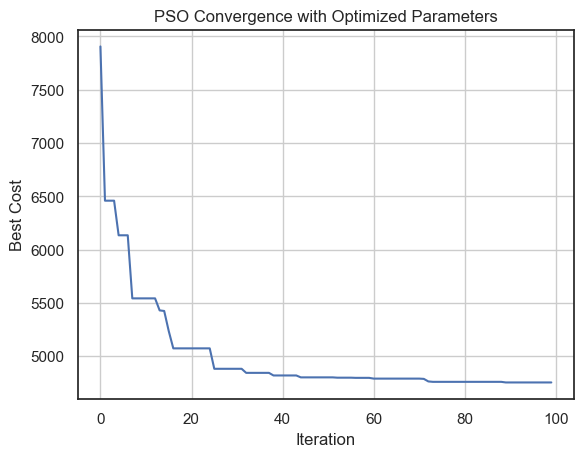

Best Cost: 4753.620251708703
Best Centroids:
 [[ 1.07783782 -0.05938822 -0.17750809  0.09050139 -0.07938183  0.05264377
  -0.02269653]
 [-1.0905408   0.14372499  0.27283231 -0.15173888  0.1518466  -0.01051387
  -0.06465868]]


In [ ]:
def compute_cost(centroids_flat, data, n_clusters):
    centroids = centroids_flat.reshape(n_clusters, -1)
    labels = pairwise_distances_argmin(data, centroids)
    cost = 0
    for i in range(len(data)):
        cost += np.linalg.norm(data[i] - centroids[labels[i]]) ** 2
    return cost

w = 0.9
personal_c =1.5
social_c = 1.5


n_particles = 30
n_iterations = 100
n_clusters = 2




dimensions = n_clusters * X_pca.shape[1]


data_min = np.min(X_pca, axis=0)
data_max = np.max(X_pca, axis=0)
pos_min = np.tile(data_min, n_clusters)
pos_max = np.tile(data_max, n_clusters)


v_max = (pos_max - pos_min) * 0.2


particles = np.random.uniform(low=pos_min, high=pos_max, size=(n_particles, dimensions))
velocities = np.random.uniform(-v_max, v_max, (n_particles, dimensions))
pbest_positions = particles.copy()
pbest_scores = np.array([compute_cost(p, X_pca, n_clusters) for p in particles])
gbest_index = np.argmin(pbest_scores)
gbest_position = pbest_positions[gbest_index].copy()
gbest_score = pbest_scores[gbest_index]

cost_history = []

for iteration in range(n_iterations):
    for i in range(n_particles):
        r1 = np.random.rand(dimensions)
        r2 = np.random.rand(dimensions)

        velocities[i] = (
            w * velocities[i]
            + personal_c * r1 * (pbest_positions[i] - particles[i])
            + social_c * r2 * (gbest_position - particles[i])
        )
        velocities[i] = np.clip(velocities[i], -v_max, v_max)

        particles[i] += velocities[i]

        particles[i] = np.clip(particles[i], pos_min, pos_max)

        cost = compute_cost(particles[i], X_pca, n_clusters)

        if cost < pbest_scores[i]:
            pbest_scores[i] = cost
            pbest_positions[i] = particles[i].copy()

        if cost < gbest_score:
            gbest_score = cost
            gbest_position = particles[i].copy()

    cost_history.append(gbest_score)
    print(f"Iteration {iteration+1}, Best Cost: {gbest_score:.6f}")

plt.plot(cost_history)
plt.xlabel('Iteration')
plt.ylabel('Best Cost')
plt.title('PSO Convergence with Optimized Parameters')
plt.grid(True)
plt.show()
f_centroids = gbest_position.reshape(n_clusters, -1)
print("Best Cost:", gbest_score)
print("Best Centroids:\n",f_centroids)


In [78]:
labels_p = pairwise_distances_argmin(X_pca, f_centroids)

print("Cluster labels for each sample:")
print(labels_p)

Cluster labels for each sample:
[0 1 0 1 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 1 0 0 0 0 0 0 0 1 0 0 0 0 1 1 0 1 0
 0 0 0 1 0 1 0 0 0 1 1 0 1 1 1 1 0 0 1 0 0 0 0 1 0 1 1 0 1 0 0 1 1 1 1 0 1
 1 1 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0 0 1 0 1 1 1 0 0 1 1 1 1 1 1 1 1 1 0 0
 1 1 0 0 0 1 1 1 0 0 1 0 1 0 0 1 0 0 1 0 0 0 1 1 1 1 1 0 1 0 1 0 0 1 0 0 0
 1 0 1 0 0 0 0 1 1 1 0 0 0 1 0 1 1 1 1 1 0 0 1 0 1 0 0 0 0 0 1 1 1 1 1 0 0
 0 0 0 1 0 0 0 1 0 1 1 0 1 1 0 1 1 0 1 0 0 1 0 1 0 0 1 0 0 0 1 1 0 0 0 1 0
 1 1 1 0 0 0 0 0 1 1 1 0 0 0 0 1 1 1 1 1 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 0 1
 1 1 0 1 1 0 0 1 1 0 1 1 0 0 0 1 1 0 1 0 0 1 0 1 0 0 0 1 0 1 1 0 0 1 0 0 1
 0 0 1 0 0 1 0 0 1 1 0 1 0 1 1 0 1 1 0 0 0 1 1 1 0 1 1 1 0 0 1 1 1 0 0 1 0
 0 0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 0 0 1 1
 1 0 0 1 1 0 0 1 1 1 1 1 1 0 0 0 1 1 0 1 1 0 1 1 1 1 0 1 1 0 1 0 0 1 1 0 0
 0 1 0 1 1 0 1 0 1 1 0 1 0 1 0 0 1 0 0 1 1 1 1 1 1 0 0 0 1 0 0 1 1 0 1 0 1
 0 1 1 1 1 1 0 1 1 1 0 0 1 1 0 1 0 1 1 1 0 0 0 1 1 0 1 0 0 1 0 0 0 0

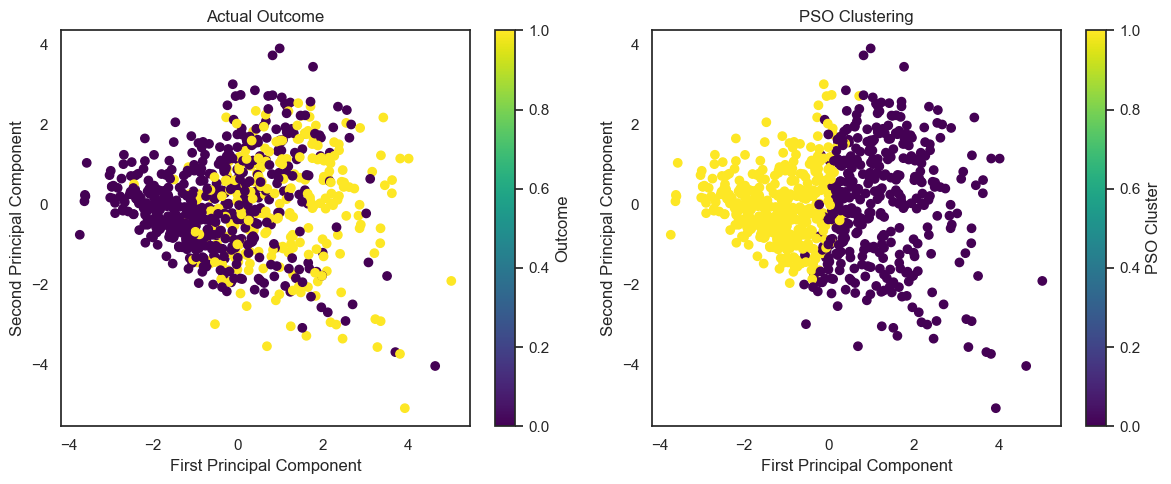

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

sc0 = axs[0].scatter(X_pca[:, 0], X_pca[:, 1], c=df_cleaned["Outcome"].values, cmap='viridis')
axs[0].set_title("Actual Outcome")
axs[0].set_xlabel("First Principal Component")
axs[0].set_ylabel("Second Principal Component")
fig.colorbar(sc0, ax=axs[0], label="Outcome")


sc1 = axs[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_p, cmap='viridis')
axs[1].set_title("PSO Clustering")
axs[1].set_xlabel("First Principal Component")
axs[1].set_ylabel("Second Principal Component")
fig.colorbar(sc1, ax=axs[1], label="PSO Cluster")

plt.tight_layout()
plt.show()

In [ ]:
sil_score = silhouette_score(X_pca, labels_p)
print(f"Silhouette Score: {sil_score:.4f}")

Silhouette Score: 0.1848


In [ ]:
def match_clusters_to_labels(true_labels, labels_p):

    contingency_matrix = np.zeros((len(set(true_labels)), len(set(labels_p))))
    for i in range(len(true_labels)):
        contingency_matrix[true_labels[i]][labels_p[i]] += 1

    row_ind, col_ind = linear_sum_assignment(-contingency_matrix)
    mapping = {col: row for row, col in zip(row_ind, col_ind)}
    pred_mapped = [mapping[c] for c in labels_p]
    return pred_mapped

y_pred_matched = match_clusters_to_labels(true_labels, labels_p)

print("Accuracy:", accuracy_score(true_labels, y_pred_matched))
print("ARI:", adjusted_rand_score(true_labels, labels_p))
print("NMI:", normalized_mutual_info_score(true_labels, labels_p))
print("FMI:", fowlkes_mallows_score(true_labels, labels_p))

Accuracy: 0.6963350785340314
ARI: 0.15318590534646012
NMI: 0.13329204619353008
FMI: 0.5959630901842634


In [116]:
print("Davies-Bouldin Index:", davies_bouldin_score(X_pca, labels_p))
print("Calinski-Harabasz Index:", calinski_harabasz_score(X_pca, labels_p))

Davies-Bouldin Index: 1.8969795339075848
Calinski-Harabasz Index: 178.71421012208575
